# Measuring the True Impact of a UGC Campaign

**The business question.** A brand runs a top-of-funnel campaign built on UGC (user-generated content: videos and posts from real customers). It builds awareness rather than driving immediate clicks. Did it actually *cause* more sales? And how much revenue did each $1 of spend create?

**Why this is hard.** Sales go up and down for many reasons: seasons, holidays, local economies. The campaign's effect is mixed in with all of them. Standard reporting tools often credit the wrong thing.

**How this notebook answers it.** We can't know the true answer for a real company, so we **build a fake but realistic one** where we decide the true answer ourselves. Then we run the standard measurement methods and check which ones find it:

1. Naive methods (what many dashboards do)
2. Experiment design: how big a test do we need?
3. Randomized geo holdout: switch the campaign off in random regions and compare
4. Difference-in-differences: compare changes over time between regions
5. Synthetic control: build a "lookalike" of the test region from other regions
6. Marketing mix model (MMM): a statistical model of all channels at once, fit twice: with a saturation curve that can only show diminishing returns, and with one that can also draw an S-curve. We compare their predicted returns at low, typical and high budgets, not just the average, because that's where the curve choice matters most

Finally, a **Monte Carlo study** repeats everything across hundreds of simulated worlds, to check which methods are reliably right and not just lucky once.

In [1]:
# Setup: load the libraries and our own simulation code.
%load_ext autoreload
%autoreload 2

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import pandas as pd
import statsmodels.formula.api as smf

import style
import numpy as np
from functools import partial
from simulate import (
    WorldConfig, adstock, analyst_view, saturation, simulate_world, true_iroas, true_response,
    intro_scenario, hot_markets_scenario, random_holdout_scenario, test_markets_scenario, always_on_scenario,
)

style.apply()

# Part I: Building the world

Sections 1–5 build the simulated brand, layer by layer, and introduce the ideas the methods rely on later. Here we see **everything**, including the hidden truth no real analyst gets: how fast each region is really growing and exactly how much each channel caused.

## 1. Building the world: sales without any marketing

We start with the simplest layer: how much each region would sell if the brand did **no marketing at all**. We call this the *baseline*. Later layers add marketing on top. Because we built the baseline ourselves, we'll always know exactly how much of the final sales the marketing caused.

### The settings

Every number that shapes the world is set in the cell below. These are **assumptions**, chosen to resemble a plausible mid-size online brand (about $470M in yearly sales). The table explains each choice.

| Setting | Value | What it means | Why this value |
|---|---|---|---|
| `n_geos` | 50 | Number of separate regions (think: US metro areas) | Real geo tests use dozens to ~200 regions (the US has 210 media markets). 50 is enough to split into test and control groups. |
| `n_days` | 730 | Two years of daily data | Methods need at least a full year of history to learn seasonal patterns, plus room for a test period. |
| `median_daily_sales` | $20,000 | A typical region's revenue per day | Sets the overall scale only. Every effect is a percentage, so conclusions don't depend on it. |
| `size_spread` | 0.6 | How unequal regions are in size | Produces regions from ~$6K to ~$72K/day: a few big cities, many mid-size ones, like real markets. |
| `mean_growth` | +5%/yr | Average yearly growth | A healthy but unremarkable brand. |
| `growth_spread` | 8 points | How much growth differs between regions | Most regions land between −3% and +13% a year. This uneven momentum becomes important later. |
| `weekend_lift` | +15% | Saturday/Sunday sales boost | Typical of consumer e-commerce, where people shop more in their free time. |
| `seasonal_amplitude` | ±20% | Yearly swing around the average | December runs ~20% above average and early summer ~20% below, a common retail pattern. |
| `noise_sd` | 5% | Fresh day-to-day randomness | Real sales never follow a perfectly smooth line. |
| `shock_sd` | 4% | "Sticky" regional shocks that last days to weeks | Local events (a heat wave, a festival, a competitor's sale) affect a region for a while, not just one day. |
| `cluster_shock_sd` | 3% | Shocks shared by neighbouring regions | Weather and local economies hit nearby markets together. |
| `shock_persistence` | 0.9 | How much of a shock carries into the next day | 90% carries over, so a shock fades by half in about a week. |
| `n_clusters` | 5 | Groups of neighbouring regions | Roughly like US census regions. |
| `growth_drift_sd` | 4%/yr | How much each region's sales level wanders | Real regions don't follow a perfectly smooth trend line; a region can drift up or down for months. |

Holidays (Black Friday +60%, Cyber Monday +40%, the run-up to Christmas +25%) are fixed calendar events built into the simulation code.

In [2]:
cfg = WorldConfig(
    n_geos=50,                  # number of regions
    n_days=730,                 # two years, starting 2024-01-01
    seed=42,                    # same seed = same random world every run
    median_daily_sales=20_000,  # typical region's daily revenue ($)
    size_spread=0.6,            # how unequal region sizes are
    mean_growth=0.05,           # average yearly growth (+5%)
    growth_spread=0.08,         # how much growth varies between regions
    weekend_lift=0.15,          # weekend sales boost (+15%)
    seasonal_amplitude=0.20,    # yearly swing (+/-20%)
    noise_sd=0.05,              # fresh day-to-day randomness (~5%)
    shock_sd=0.04,              # sticky regional shocks (~4%)
    cluster_shock_sd=0.03,      # shocks shared by neighbouring regions (~3%)
    shock_persistence=0.9,      # a shock keeps 90% of its size into the next day
    n_clusters=5,               # groups of neighbouring regions
    growth_drift_sd=0.04,       # each region's sales level wanders ~4% over a year
)

geos, panel = simulate_world(cfg)

### How each day's sales are calculated

For each region on each day, the simulation multiplies six pieces together:

**sales = region size × growth × day of week × season × holiday × random noise**

For example, a region with $20,000 typical sales on a Saturday in December might get: $20,000 × 1.03 (growth so far) × 1.15 (weekend) × 1.20 (December) × 1.00 (not a holiday) × 0.97 (an unlucky day) ≈ **$27,600**.

The **noise** piece combines four kinds of randomness: fresh daily noise, sticky regional shocks, shocks shared with neighbouring regions, and a slow wander in each region's sales level. Chart 2b below shows why the "sticky" kind matters.

Using multiplication (instead of adding fixed dollar amounts) means a +20% December bump is +20% for small and large regions alike, which is how real sales behave.

### What the data looks like

The result is a table with **one row per region per day**: 50 regions × 730 days = 36,500 rows.

In [3]:
print(f"{panel['geo'].nunique()} regions x {panel['date'].nunique()} days = {len(panel):,} rows")
panel.head()

50 regions x 730 days = 36,500 rows


,geo,date,baseline_sales
0,geo_00,2024-01-01,31931.024712
1,geo_00,2024-01-02,34708.570147
2,geo_00,2024-01-03,30763.641167
3,geo_00,2024-01-04,30823.503933
4,geo_00,2024-01-05,30657.173596


And here is a summary of the 50 regions themselves. `base_sales` is each region's typical daily revenue. `growth_rate` is its hidden yearly growth, which a real analyst would never see directly.

In [4]:
geos[["base_sales", "growth_rate"]].describe().loc[["mean", "min", "50%", "max"]].style.format({"base_sales": "${:,.0f}", "growth_rate": "{:+.1%}"})

,base_sales,growth_rate
mean,"$23,399",+3.5%
min,"$6,203",-8.5%
50%,"$22,199",+2.7%
max,"$72,293",+17.0%


### Chart 1: total sales across all regions

This chart adds up all 50 regions into one line: the brand's total daily sales over two years, **before any marketing**. It's a sanity check that the simulated business looks like a real one.

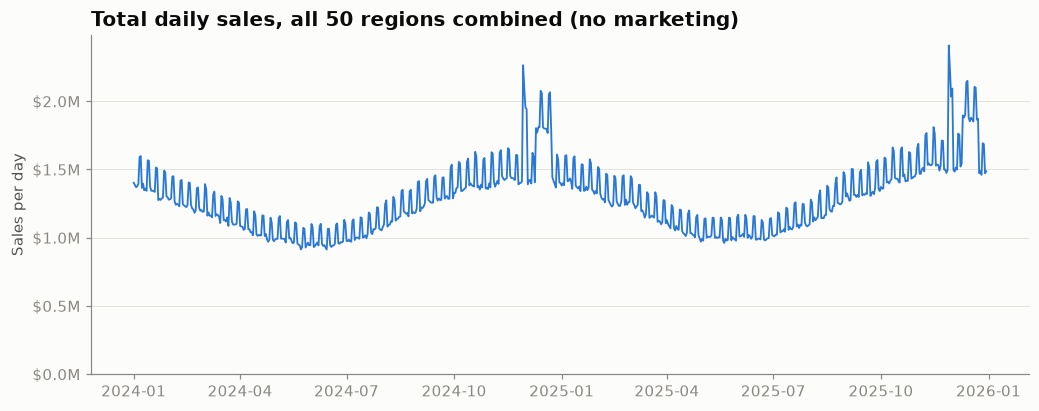

In [5]:
total = panel.groupby("date")["baseline_sales"].sum() / 1e6

fig, ax = plt.subplots()
ax.plot(total.index, total.values, linewidth=1.2)
ax.set_title("Total daily sales, all 50 regions combined (no marketing)")
ax.set_ylabel("Sales per day")
ax.yaxis.set_major_formatter(mticker.FormatStrFormatter("$%.1fM"))
ax.set_ylim(bottom=0)
plt.show()

**How to read it:**
- **The slow wave:** sales dip in early summer and peak every December. That's the seasonal pattern.
- **The sharp spikes in late November:** Black Friday and Cyber Monday, followed by the pre-Christmas rush.
- **The tight zig-zag:** the weekly cycle. Every weekend sells a bit more than the weekdays around it.
- **Year 2 sits higher than year 1:** the average region is growing.
- **Small wobbles everywhere:** randomness. Adding up 50 regions smooths most of it away; individual regions are much bumpier.

This is the "background noise" any measurement method must see through. A campaign launched in October would look like a huge success just because sales rise into the holidays, even if it did nothing.

### Chart 2: why regions behave differently

Now we zoom in on four individual regions: the slowest-growing, two in the middle, and the fastest-growing.

Two adjustments make them comparable:
- **Indexing:** regions differ hugely in size (about $6K to $72K a day), so each region gets its own **base**: its average daily sales over its first 28 days (Jan 1–28, 2024). Every point is divided by that base and multiplied by 100. The unit changes from dollars to "percent of where this region started": 100 = same as its first 28 days, 120 = 20% above, 80 = 20% below. For example, a big region going from $60,000 to $66,000 a day and a small one going from $6,000 to $6,600 both read 100 → 110, because both grew 10%. We give up seeing region *size* on purpose, so we can compare *growth*. In plain dollars, the small regions would be squashed flat at the bottom of the chart.
- **Smoothing:** each point is itself the average of the previous 28 days, which irons out the weekly zig-zag so the trend is easier to see. That's also why the lines start on Jan 28: the first 28-day average needs 28 days of data. And that first point is exactly 100, because it *is* the base divided by itself.

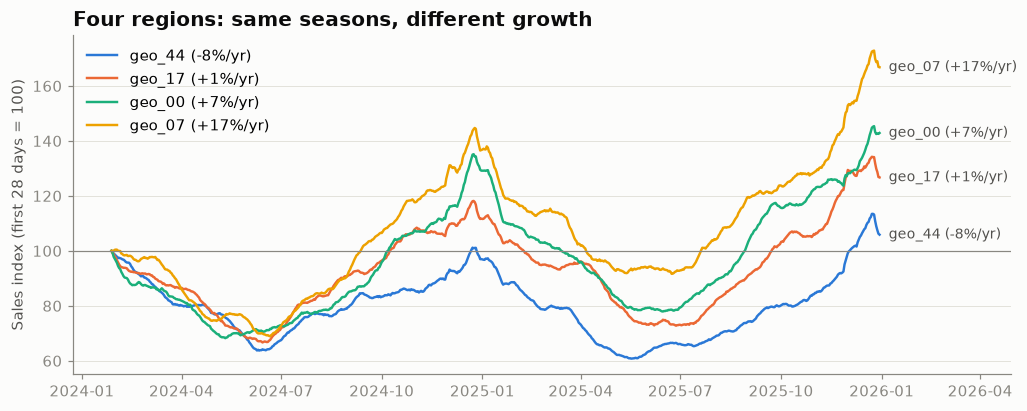

In [6]:
picks = geos.sort_values("growth_rate").iloc[[0, 16, 33, 49]]
wide = panel.pivot(index="date", columns="geo", values="baseline_sales")[picks["geo"]]
base = wide.iloc[:28].mean()                    # each region's average over its first 28 days
indexed = wide.rolling(28).mean() / base * 100  # each point: 28-day average, as % of that base

fig, ax = plt.subplots()
for (_, row), color in zip(picks.iterrows(), style.SERIES):
    s = indexed[row["geo"]]
    label = f"{row['geo']} ({row['growth_rate']:+.0%}/yr)"
    ax.plot(s.index, s.values, color=color, label=label)
    ax.annotate(label, (s.index[-1], s.iloc[-1]), xytext=(6, 0), textcoords="offset points",
                va="center", fontsize=9, color=style.INK_SECONDARY)
ax.axhline(100, color=style.MUTED, linewidth=0.8)
ax.set_title("Four regions: same seasons, different growth")
ax.set_ylabel("Sales index (first 28 days = 100)")
ax.legend(loc="upper left")
ax.set_xlim(right=indexed.index[-1] + pd.Timedelta(days=120))
plt.show()

**How to read it:** all four lines rise and fall together, because they share the same seasons and holidays. But they **drift apart**: by the end, the fastest region (+17%/yr) sits far above the slowest (−8%/yr).

**Why this matters for the rest of the project:** on any single day, you can't tell a fast-growing region from a slow one, because the seasonal swings are much bigger than the growth difference. But a marketer watching regional reports over months *will* notice which regions are "hot" and tend to put more budget there. If those regions were going to grow anyway, a naive analysis will credit the campaign for growth it didn't cause. We'll build exactly that trap in a later layer, then see which methods fall into it.

### Chart 2b: two kinds of randomness

Real sales don't just wobble randomly from one day to the next. A heat wave, a local festival or a competitor's sale can lift or depress a region for days or weeks. We call these **sticky shocks**: each day keeps 90% of yesterday's shock and adds a small fresh one, so a shock fades by half in about a week. Some shocks hit a whole group of neighbouring regions at once (weather, the local economy), and each region's sales level also wanders slowly over time.

This matters because sticky noise doesn't average out quickly. Two weeks of fresh noise mostly cancels out; two weeks of sticky noise can push a whole region up or down. That makes experiments harder, which is realistic.

The chart compares the two kinds, using the same typical size (4%) for both:

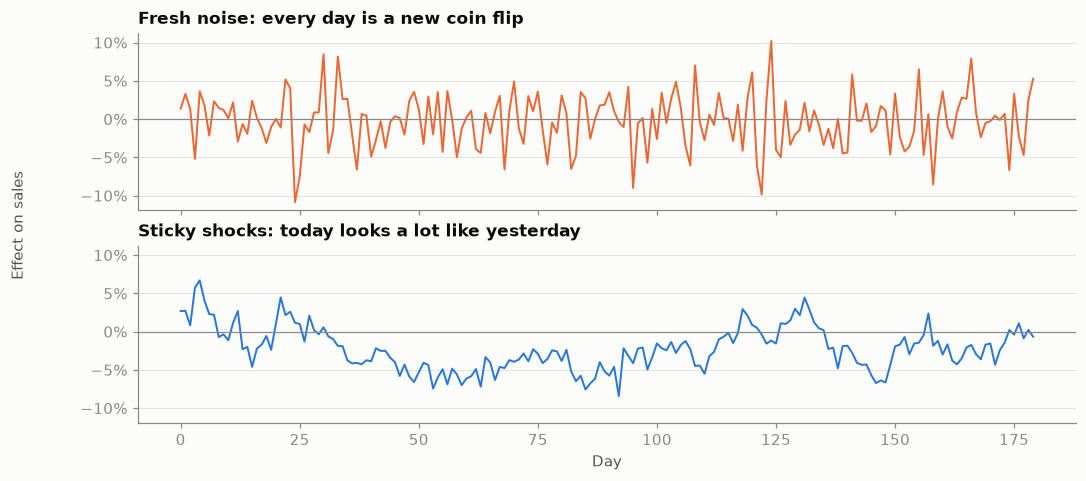

In [7]:
from simulate import sticky_shocks

demo_rng = np.random.default_rng(1)
fresh_demo = demo_rng.normal(0, 0.04, 180)
sticky_demo = sticky_shocks(1, 180, sd=0.04, persistence=0.9, rng=demo_rng)[0]

fig, axes = plt.subplots(2, 1, figsize=(11, 4.6), sharex=True, sharey=True)
for ax, series, title, color in [(axes[0], fresh_demo, "Fresh noise: every day is a new coin flip", style.SERIES[1]),
                                 (axes[1], sticky_demo, "Sticky shocks: today looks a lot like yesterday", style.SERIES[0])]:
    ax.plot(series, color=color, linewidth=1.3)
    ax.axhline(0, color=style.MUTED, linewidth=0.8)
    ax.set_title(title, fontsize=11)
    ax.yaxis.set_major_formatter(mticker.PercentFormatter(1.0, decimals=0))
axes[1].set_xlabel("Day")
fig.supylabel("Effect on sales", fontsize=10, color=style.INK_SECONDARY)
plt.show()

**How to read it:** both lines have the same typical size, but the top one zig-zags around zero while the bottom one wanders off for stretches of days, above or below zero. In a two-week window, the top line averages out to almost nothing; the bottom one may not. Our simulated regions have both kinds, plus shocks shared by neighbours and a slow wander in each region's level.

## 2. Adstock: ads keep working after the day they run

People rarely buy the moment they see an ad. Someone watches a customer's UGC video on Monday, remembers the brand, and buys on Friday. So an ad's effect doesn't stop when the spending stops. It fades out gradually.

Marketers model this with **adstock**: a running tally of how much "ad memory" is still active in people's minds. Each day:

**ad memory today = today's spend + carryover × yesterday's ad memory**

**Carryover** is the share of yesterday's memory that survives to today. With a carryover of 0.7 (70%), the effect roughly halves every two days.

### A single burst of spend

Suppose a region gets $10,000 of UGC spend on Monday and nothing after that:

In [8]:
days = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
spend = np.array([10_000, 0, 0, 0, 0, 0, 0])

pd.DataFrame({
    "day": days,
    "spend": spend,
    "ad memory (carryover 0.7)": adstock(spend, carryover=0.7).round(),
}).style.format({"spend": "${:,.0f}", "ad memory (carryover 0.7)": "${:,.0f}"}).hide(axis="index")

day,spend,ad memory (carryover 0.7)
Mon,"$10,000","$10,000"
Tue,$0,"$7,000"
Wed,$0,"$4,900"
Thu,$0,"$3,430"
Fri,$0,"$2,401"
Sat,$0,"$1,681"
Sun,$0,"$1,176"


Monday's $10,000 keeps working all week: $7,000 of effect on Tuesday, $4,900 on Wednesday, and so on.

Add up the whole fading tail and the total ad memory is about **$33,333**, more than 3× what shows up on Monday. In other words, **only 30% of the ad memory is active on the day of spending.** (The share of extra *sales* on day one differs a little once the saturation curve in section 3 is applied, but the point holds.) Any measurement that only counts sales on the day of the ad, or within a short window after it, as many attribution tools do, misses most of the effect and makes the campaign look weaker than it is.

### Chart 3: a four-week campaign

Real campaigns spend steadily for weeks, not just one day. This chart runs the same campaign ($10,000 a day for four weeks, shaded in gray) under three carryover levels, to show how the shape of the effect changes.

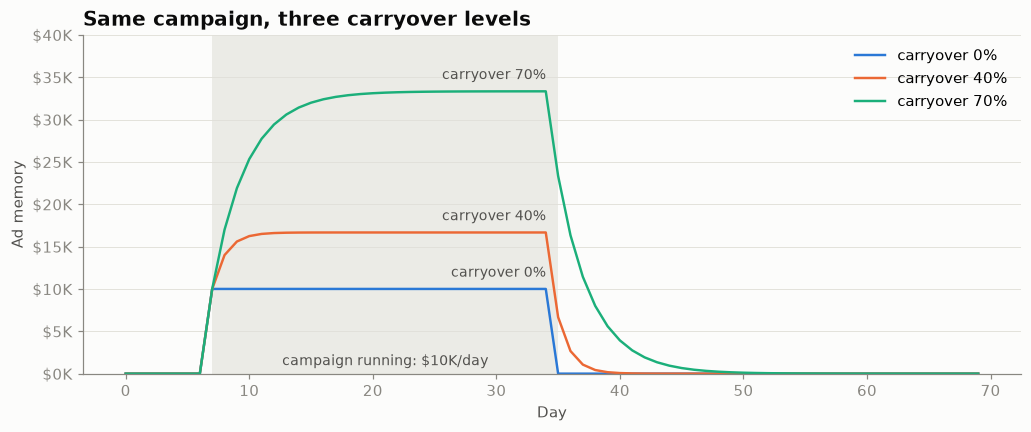

In [9]:
n_days = 70
flight = np.zeros(n_days)
flight[7:35] = 10_000  # campaign runs days 7-34

fig, ax = plt.subplots()
ax.axvspan(7, 35, color=style.GRID, alpha=0.6, linewidth=0)
for carry, color in zip([0.0, 0.4, 0.7], style.SERIES):
    memory = adstock(flight, carryover=carry) / 1000
    label = f"carryover {carry:.0%}"
    ax.plot(memory, color=color, label=label)
    ax.annotate(label, (34, memory[34]), xytext=(0, 8), textcoords="offset points",
                ha="right", fontsize=9, color=style.INK_SECONDARY)
ax.text(21, 1, "campaign running: $10K/day", ha="center", fontsize=9, color=style.INK_SECONDARY)
ax.set_title("Same campaign, three carryover levels")
ax.set_xlabel("Day")
ax.set_ylabel("Ad memory")
ax.yaxis.set_major_formatter(mticker.FormatStrFormatter("$%.0fK"))
ax.set_ylim(0, 40)
ax.legend(loc="upper right")
plt.show()

**How to read it:**
- **No carryover (blue):** the effect switches on and off exactly with the spending. This is what naive analysis implicitly assumes.
- **70% carryover (green):** the effect *builds up* over the first week, levels off at about 3.3× the daily spend, and then *fades out* over the week after the campaign ends.

**Why this matters later:**
1. **Experiments must keep measuring after the campaign ends,** or they miss the tail. Our geo holdout will include a "cooldown" period.
2. **Different channels fade at different speeds.** UGC builds awareness, so its effect lingers (high carryover). A search ad catches someone who is already looking to buy, so its effect is almost immediate (low carryover). We'll set each channel's carryover when we add the channels in layer 4.

**What's still missing:** "ad memory" is measured in dollars of *spend*, not dollars of *sales*. The next layer, **saturation**, converts ad memory into extra sales, with diminishing returns as spending grows.

## 3. Saturation: each extra dollar does a little less

If a region's UGC budget doubles, do the extra sales double? Usually not, for three reasons:
- **The most receptive people are reached first.** Early dollars find the people most likely to buy. Later dollars reach people who are less interested.
- **Repeat exposure.** More spend often shows the *same* people the ad again, and the fifth viewing persuades less than the first.
- **Rising cost per new person.** Reaching new audiences gets more expensive as you go.

This is **diminishing returns**, which marketers call **saturation**. We model it with the **Hill curve**, a standard choice in marketing mix models. It turns ad memory (from layer 2) into a share of the *maximum possible* effect, between 0% and 100%.

### Two possible shapes

Real channels tend to follow one of two shapes. We show both here so you can compare them. In section 4, **each channel gets just one**: search and social get the first, UGC gets the second.

- **Diminishing returns** (shape 1). Like a glass of water when you're thirsty: the first glass helps a lot, the fifth barely at all. The very first dollars do the most good. This fits **search**: the ad catches someone who is already looking to buy.
- **S-curve** (shape 2). Like a catchy song on the radio: hearing it once does nothing, by the third time it's stuck in your head, after the twentieth time more plays add nothing. A little spend barely registers, then the effect kicks in, then it flattens. This fits **UGC**: awareness builds through repeated exposure.

Both shapes share one more setting, the **half point**: the amount of ad memory that gets you halfway to the maximum effect.

### Doubling the budget: a worked example

Give both curves the same settings:
- The most the campaign could ever add is **$20,000 of extra sales per day**.
- The half point is **$20,000 of ad memory**, so at that level you get half the maximum: $10,000 a day.

Now double the budget. With steady daily spending, ad memory grows in proportion to spend, so doubling the budget doubles ad memory: from **$10K to $20K**. How much do extra sales grow under each shape?

In [10]:
max_effect, half = 20_000, 20_000
rows = []
for shape, name in [(1, "Shape 1 (diminishing)"), (2, "Shape 2 (S-curve)")]:
    low, high = max_effect * saturation(np.array([10_000, 20_000]), half, shape)
    rows.append({"curve": name, "extra sales at $10K": low, "extra sales at $20K": high, "growth when doubled": high / low})

pd.DataFrame(rows).style.format({
    "extra sales at $10K": "${:,.0f}", "extra sales at $20K": "${:,.0f}", "growth when doubled": "{:.1f}x",
}).hide(axis="index")

curve,extra sales at $10K,extra sales at $20K,growth when doubled
Shape 1 (diminishing),"$6,667","$10,000",1.5x
Shape 2 (S-curve),"$4,000","$10,000",2.5x


Both curves end at the same place, $10,000 of extra sales, because $20K is the half point and that's the definition of the half point. The difference is where they **start**:

- **Diminishing returns: 1.5×** the sales for 2× the money. At $10K this curve was already doing well, because its first dollars were the most productive. The extra dollars add less.
- **S-curve: 2.5×** the sales for 2× the money. At $10K this curve was still in its "barely registering" zone. Doubling the budget pushed it into the steep part, where it gains a lot.

So "will doubling spend double sales?" depends on **which shape** the channel has and **where on the curve** the current budget sits.

**Why this matters later:** the measurement methods never see the true shape. They have to infer it from the data. The marketing mix model (MMM, later in this notebook) estimates a curve for each channel, and if it gets UGC's shape wrong, its answer for UGC will be off.

### Chart 4: the two shapes side by side

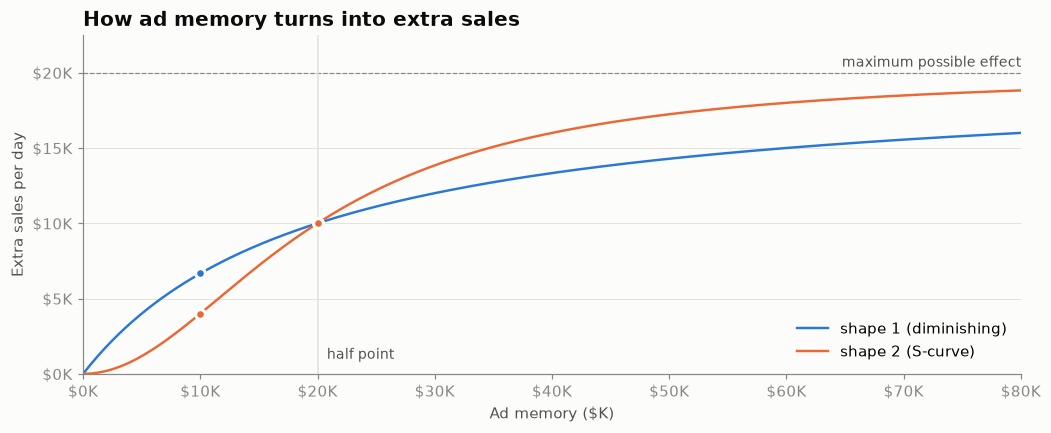

In [11]:
x = np.linspace(0, 80_000, 400)

fig, ax = plt.subplots()
ax.axhline(max_effect / 1000, color=style.MUTED, linewidth=0.8, linestyle="--")
ax.text(80, max_effect / 1000 + 0.4, "maximum possible effect", ha="right", fontsize=9, color=style.INK_SECONDARY)
for shape, name, color in [(1, "shape 1 (diminishing)", style.SERIES[0]), (2, "shape 2 (S-curve)", style.SERIES[1])]:
    y = max_effect * saturation(x, half, shape) / 1000
    ax.plot(x / 1000, y, color=color, label=name)
    pts = np.array([10_000, 20_000])
    ax.scatter(pts / 1000, max_effect * saturation(pts, half, shape) / 1000, s=40, color=color,
               edgecolor=style.SURFACE, linewidth=2, zorder=3)
ax.axvline(half / 1000, color=style.GRID, linewidth=1)
ax.text(half / 1000 + 0.8, 1, "half point", fontsize=9, color=style.INK_SECONDARY)
ax.set_title("How ad memory turns into extra sales")
ax.set_xlabel("Ad memory ($K)")
ax.set_ylabel("Extra sales per day")
ax.xaxis.set_major_formatter(mticker.FormatStrFormatter("$%.0fK"))
ax.yaxis.set_major_formatter(mticker.FormatStrFormatter("$%.0fK"))
ax.yaxis.set_major_locator(mticker.MultipleLocator(5))
ax.set_ylim(0, 22.5)
ax.set_xlim(0, 80)
ax.legend(loc="lower right")
plt.show()

**How to read it:** both curves rise and then flatten toward the dashed ceiling. No amount of spend can push past it. The dots mark $10K and $20K of ad memory from the example above.
- The **blue curve** is steepest at the very start: the first dollars are the most productive.
- The **orange S-curve** starts flat, rises fastest around the half point, then flattens.
- Both cross the half point at exactly half of the maximum effect ($10K), which is what "half point" means.

**Why this matters later: there is no single "return on ad spend."** On a flattening curve, the *last* dollar spent earns less than the *average* dollar. At $20K of ad memory on the blue curve, the average dollar of ad memory returns $0.50, but the next one returns only about $0.25. When we define the campaign's "true" return, we must say which one we mean. Experiments measure the *average* return of the spend they test, and budget decisions need the *marginal* one (the return on the next dollar).

**Next:** layer 4 puts the pieces together. We add the actual channels (UGC, paid search, paid social), give each its own carryover and saturation settings, and add the **halo**: UGC making people search for the brand.

## 4. The marketing channels: putting it all together

Now we give the brand three marketing channels. Each one runs through the same recipe from layers 2 and 3:

**spend → ad memory (carryover) → saturation curve → extra sales**

The channels differ in how quickly their effect fades and how their returns flatten:

| Channel | Carryover | Curve | Why |
|---|---|---|---|
| **Paid search** | 20% | Diminishing | The person was already searching for the product, so the ad works almost immediately and fades fast. |
| **Paid social** | 40% | Diminishing | In between: people scroll past, some remember it for a few days. |
| **UGC** | 70% | S-curve | It builds awareness, which lingers. People usually need several exposures before it sinks in, so small budgets barely register. Its usual budget sits around the steep middle of the S, so smaller and bigger flights reach the flat start and the flattening top. |

Two more details:
- **Sizes scale with the region.** Each channel's half point and maximum effect are set as a share of the region's typical daily sales, so a big city needs proportionally more spend before it saturates than a small one.
- **UGC works better in some regions than others.** Each region has a hidden *responsiveness* that multiplies UGC's effect (1.0 = average). **This is an assumption we chose**, not something the data forces: we link responsiveness partly to growth, so UGC tends to work a bit better where sales are already growing. It's plausible (a market gaining momentum often has an engaged audience and word of mouth already going, which is what UGC feeds on), and it creates a real measurement problem: if a marketer picks fast-growing regions, the effect measured there won't be the effect elsewhere. The link is one setting (`ugc_response_growth_link = 0.5`); setting it to 0 removes it.
- **The halo.** Some people who watch a UGC video don't buy right away. Instead they later Google the brand and buy through a search ad. Those sales were *caused* by UGC but look like *search* sales. We set the halo at 50%: for every $1 of sales UGC drives directly, another $0.50 arrives through branded search.
- **What the ad platforms report.** Google, Meta and others each report the revenue they "drove", usually using **last-click attribution**: a sale counts for whichever ad was clicked last before buying. Platforms count *clicks*, and clicks follow *spend*, not what the ad actually caused. So we build the reports from spend, with their own noise, and never from the true effect:
  - **Search** claims revenue from its paid clicks, from branded searches that UGC set off (the halo), *and* from loyal customers who google the brand and click the top ad on their way to buying anyway (about 8% of usual sales).
  - **Social** claims less than it really causes: many people it persuades see a post but never click it.
  - **UGC** gets credit for almost nothing, because people rarely click a UGC video right before buying.
  - Tracking is also imperfect: it works better in some regions than others and wobbles week to week.

### A first campaign

For now we use a simple intro scenario: search and social run all the time, and UGC runs in **every region** for an 8-week flight (March 1 – April 25, 2025). Spend levels are a share of each region's typical daily sales: search 5%, social 4%, UGC 2%. While UGC runs, it lifts sales by about 2–3%, a realistic size for a top-of-funnel campaign and hard to see through the noise.

In [12]:
intro = partial(intro_scenario, ugc_start="2025-03-01", ugc_end="2025-04-25")
geos, panel = simulate_world(cfg, scenario=intro)

panel.columns.tolist()

['geo',
 'date',
 'true_baseline_sales',
 'spend_search',
 'spend_social',
 'spend_ugc',
 'reported_search',
 'reported_social',
 'reported_ugc',
 'true_effect_search',
 'true_effect_social',
 'true_effect_ugc',
 'true_effect_ugc_halo',
 'sales']

The data now has two kinds of columns:
- **What an analyst would actually see:** `geo`, `date`, the three `spend_` columns, the three `reported_` columns (what each ad platform claims it drove), and total `sales`.
- **The hidden truth** (everything starting with `true_`): the baseline, and exactly how many extra sales each channel caused. A real company never gets these. We keep them only to grade the methods. Each region's UGC responsiveness is hidden too.

### Chart 5: where one region's extra sales come from

This chart zooms in on one typical region from February to June 2025. It shows only the *extra* sales marketing caused (not the baseline), stacked by channel. The gray band is the UGC flight.

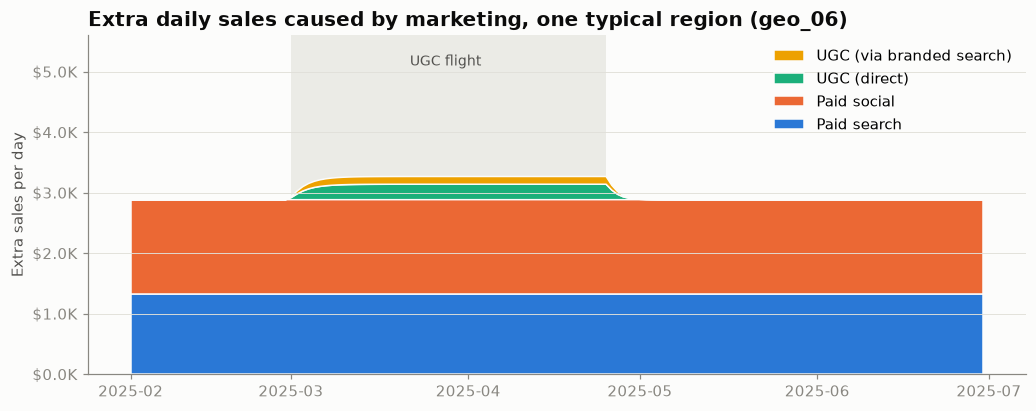

In [13]:
typical = geos.iloc[(geos["base_sales"] - geos["base_sales"].median()).abs().argmin()]["geo"]
one = panel[(panel["geo"] == typical) & panel["date"].between("2025-02-01", "2025-06-30")].set_index("date")

layers = {
    "Paid search": one["true_effect_search"],
    "Paid social": one["true_effect_social"],
    "UGC (direct)": one["true_effect_ugc"],
    "UGC (via branded search)": one["true_effect_ugc_halo"],
}
fig, ax = plt.subplots()
ax.axvspan(pd.Timestamp("2025-03-01"), pd.Timestamp("2025-04-25"), color=style.GRID, alpha=0.6, linewidth=0)
ax.stackplot(one.index, [v / 1000 for v in layers.values()], labels=layers.keys(),
             colors=style.SERIES[:4], edgecolor=style.SURFACE, linewidth=1)
ax.text(pd.Timestamp("2025-03-28"), 5.1, "UGC flight", ha="center", fontsize=9, color=style.INK_SECONDARY)
ax.set_title(f"Extra daily sales caused by marketing, one typical region ({typical})")
ax.set_ylabel("Extra sales per day")
ax.yaxis.set_major_formatter(mticker.FormatStrFormatter("$%.1fK"))
ax.set_ylim(0, 5.6)
ax.legend(loc="upper right", reverse=True)
plt.show()

**How to read it:**
- **Blue and orange (search and social)** sit steady all period, because in this intro scenario they run all the time at a fixed budget.
- **Green (UGC direct)** appears when the flight starts. It takes about a week to build up (carryover plus the S-curve: it needs a few exposures to sink in), holds through the flight, and fades out over about a week after it ends.
- **Yellow (UGC via branded search)** follows UGC exactly, at half its size. This slice is the halo. In an attribution dashboard it would be credited to *search*.

### The true answer

Here is the real return on each channel: total extra revenue caused, divided by total spend. For UGC, the halo counts, because UGC caused those sales too.

In [14]:
channels = ["search", "social", "ugc"]
pd.DataFrame({
    "channel": ["Paid search", "Paid social", "UGC"],
    "total spend": [panel[f"spend_{c}"].sum() for c in channels],
    "true iROAS": [true_iroas(panel, c) for c in channels],
    "platform-reported ROAS": [panel[f"reported_{c}"].sum() / panel[f"spend_{c}"].sum() for c in channels],
}).style.format({"total spend": "${:,.0f}", "true iROAS": "${:.2f}", "platform-reported ROAS": "${:.2f}"}).hide(axis="index")

channel,total spend,true iROAS,platform-reported ROAS
Paid search,"$42,702,821",$1.22,$3.33
Paid social,"$34,162,257",$1.82,$1.39
UGC,"$1,310,333",$1.32,$0.10


**iROAS** (incremental return on ad spend) = extra revenue *caused* per $1 spent. **Platform-reported ROAS** = the revenue each platform *claims* under last-click, per $1 spent.

**UGC's true iROAS in this intro scenario is about $1.32.** But look at what the platforms report:
- **Search claims $3.33** per $1, about 2.7× its real return. It's taking credit for UGC's halo and for loyal customers who would have bought anyway.
- **Social claims $1.39**, *less* than its real $1.82, because many people it persuades never click.
- **UGC gets credit for just $0.10** per $1. A dashboard would say UGC is nearly worthless and should be cut, when it actually returns $1.32.

This is the core problem the project is about: the numbers marketers see every day can point in exactly the wrong direction.

There's also a catch in this intro scenario: UGC ran in *every* region at the *same* time. There is no comparison group, and the flight overlaps with seasonal changes in spring sales. The next layer fixes that, and adds the trap: **scenarios** for where the money goes, including one where the marketer puts more money into regions that were already growing.

## 5. Four scenarios: who gets UGC, when, and how much

The last layer decides *where and when the money goes*. This is where real-world measurement gets hard, because marketers don't spend at random. We build four **scenarios**: four situations an analyst could walk into, each with its own true answer. Each one suits a different measurement method.

| Scenario | What the marketer does | What it sets up |
|---|---|---|
| **Hot markets** | Launches UGC on March 1, 2025 in the 20 regions that *look* like they're growing fastest, and runs it through November | **The trap.** UGC lands where sales were going to grow anyway. |
| **Random holdout** | A coin flip picks 25 of the 50 regions to get UGC for an 8-week test (March 1 – April 25, 2025). The other 25 are the control group | The **geo experiment**, the gold standard |
| **Test markets** | Tries UGC in 3 typical regions (mid-sized and growing at an ordinary pace) for three months (April – June 2025) | **Synthetic control**, built for "only a few regions got it" |
| **Always-on** | Runs UGC in 6-week flights with 6-week breaks. Each region gets its own budget for each flight (from 0.2× to 2× the usual level) and occasionally sits one out | The **marketing mix model**, which needs spend that goes up and down |

**How the marketer picks hot markets.** They can't see each region's true growth rate; nobody can. They see a noisy read of it from reports and gut feel, and pick the top 20 on that read. Because the read is roughly right, the picks lean heavily toward truly fast-growing regions.

**Search and social in every scenario.** Both run all the time, like real budgets: the national budget moves up and down by about 15% week to week, each region's budget wobbles about 10% more on top, and everything rises about 30% in Q4 (October to December). That Q4 rise is a quieter trap. Spend goes up exactly when sales would rise anyway, so a careless analysis will credit the ads for the holiday season.

All four scenarios run on **the same simulated world**: the same regions, the same baseline sales, day for day. Only the spending differs.

In [15]:
scenarios = {
    "Hot markets": hot_markets_scenario,
    "Random holdout": random_holdout_scenario,
    "Test markets": test_markets_scenario,
    "Always-on": always_on_scenario,
}
worlds = {name: simulate_world(cfg, scenario=s) for name, s in scenarios.items()}

### Chart 6: where the UGC money went

Each panel is one scenario. Every **row is a region** and every **column is a day**. Darker blue means more UGC spend in that region on that day, measured against the usual level (2% of the region's typical daily sales): 100% means the usual budget, 200% means double.

The rows are sorted by each region's **hidden growth rate**: fastest-growing at the top, slowest at the bottom. A real analyst could never sort them this way. We can, because we built the world, and it makes the trap visible.

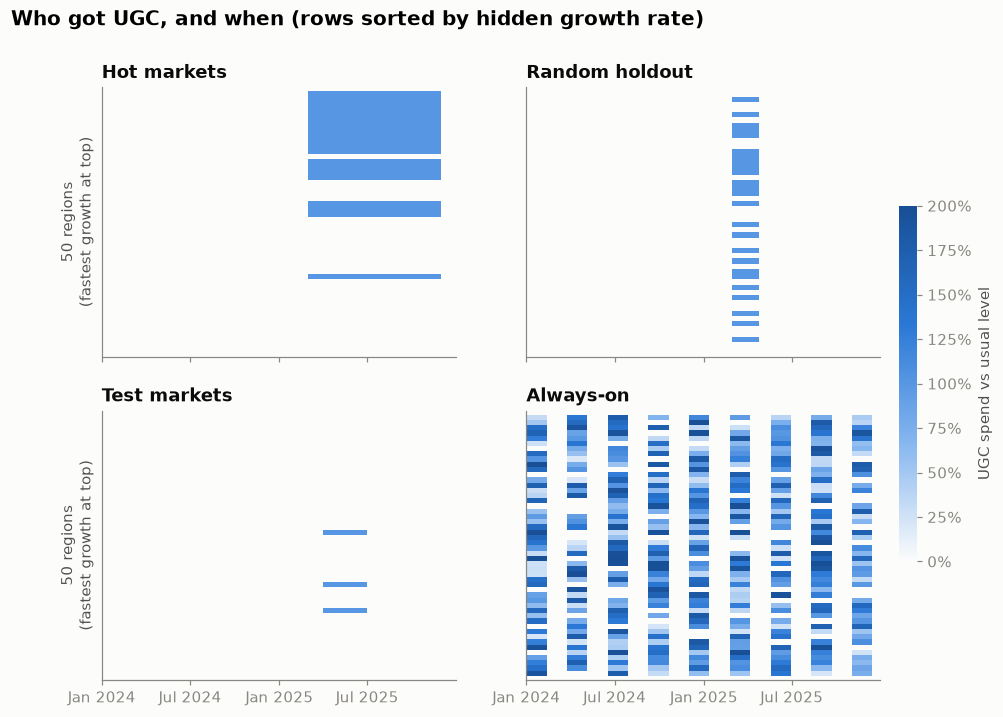

In [16]:
from matplotlib.colors import LinearSegmentedColormap
from simulate import LEVELS

blues = LinearSegmentedColormap.from_list("ugc", [style.SURFACE, "#86b6ef", style.SERIES[0], "#184f95"])
order = geos.sort_values("growth_rate", ascending=False)["geo"]
size = geos.set_index("geo")["base_sales"]

fig, axes = plt.subplots(2, 2, figsize=(11, 7), sharex=True, sharey=True)
for ax, (name, (_, p)) in zip(axes.flat, worlds.items()):
    grid = p.pivot(index="geo", columns="date", values="spend_ugc").loc[order]
    intensity = grid.div(size.loc[order], axis=0) / LEVELS["ugc"]
    dates = grid.columns
    img = ax.imshow(intensity.to_numpy(), aspect="auto", cmap=blues, vmin=0, vmax=2.0, interpolation="nearest",
                    extent=[mdates.date2num(dates[0]), mdates.date2num(dates[-1]), len(order), 0])
    ax.set_title(name, fontsize=12)
    ax.grid(False)
    ax.set_yticks([])
    ax.set_ylim(len(order) + 0.8, -0.8)  # small margin so edge rows stay visible
    ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 7]))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
for ax in axes[:, 0]:
    ax.set_ylabel("50 regions\n(fastest growth at top)")
cbar = fig.colorbar(img, ax=axes, shrink=0.6, pad=0.02)
cbar.set_label("UGC spend vs usual level")
cbar.outline.set_visible(False)
cbar.ax.yaxis.set_major_formatter(mticker.PercentFormatter(1.0))
fig.suptitle("Who got UGC, and when (rows sorted by hidden growth rate)", x=0.05, ha="left", fontweight="bold", fontsize=13)
plt.show()

**How to read it:**
- **Hot markets:** the blue block sits mostly in the **top half**. UGC went to the regions that were already growing fastest. That's the trap, in one picture.
- **Random holdout:** the blue stripes are **scattered** from top to bottom. The coin flip ignored growth, so fast and slow regions both got UGC.
- **Test markets:** only **three thin stripes**, three regions, for three months, all from the middle rows: ordinary growth, as the marketer intended.
- **Always-on:** on/off flights across all regions, but each region has its own shade in each flight because its budget differs, and a few cells are blank where a region sat a flight out. That variety, across regions *and* over time, is what lets an MMM learn the shape of the response curve.

### Checking the trap with numbers

For each scenario: the average hidden growth rate and hidden UGC responsiveness of the regions that got UGC, compared with the regions that didn't.

In [17]:
rows = []
for name, (g, p) in worlds.items():
    got_ugc = (p.groupby("geo")["spend_ugc"].sum() > 0).to_numpy()
    rows.append({
        "scenario": name,
        "regions with UGC": int(got_ugc.sum()),
        "growth: UGC regions": g["growth_rate"][got_ugc].mean(),
        "growth: other regions": g["growth_rate"][~got_ugc].mean() if (~got_ugc).any() else None,
        "UGC responsiveness: UGC regions": g["ugc_response"][got_ugc].mean(),
        "UGC responsiveness: other regions": g["ugc_response"][~got_ugc].mean() if (~got_ugc).any() else None,
    })
pd.DataFrame(rows).style.format({
    "growth: UGC regions": "{:+.1%}", "growth: other regions": "{:+.1%}",
    "UGC responsiveness: UGC regions": "{:.2f}", "UGC responsiveness: other regions": "{:.2f}",
}, na_rep="(none)").hide(axis="index")

scenario,regions with UGC,growth: UGC regions,growth: other regions,UGC responsiveness: UGC regions,UGC responsiveness: other regions
Hot markets,20,+8.9%,-0.2%,1.17,0.81
Random holdout,25,+4.5%,+2.4%,0.94,0.96
Test markets,3,+1.8%,+3.6%,0.93,0.95
Always-on,50,+3.5%,(none),0.95,(none)


- **Hot markets:** the UGC regions were growing about **9 points a year faster** before any campaign. Any method that compares UGC regions with the rest, or compares their growth before and after launch, will mistake part of that head start for the campaign's effect.
- **Random holdout:** a smaller gap (+4.5% vs +2.4%), purely by **luck of the draw**. A coin flip balances the groups *on average*, but any single flip of 50 regions can leave a gap. The Monte Carlo study will show that across hundreds of flips the gap averages out to zero. Within a single experiment, adjusting for each region's pre-test sales (a technique called **CUPED**, see the companion note) reduces noise and corrects some of the chance imbalance.
- **Responsiveness:** in hot markets, UGC also lands where it works better (1.17 vs 0.81), because we built responsiveness to be partly linked to growth (section 4). So even a perfect measurement there tells you what UGC did *in hot markets*, not what it would do if rolled out everywhere. In the random holdout, the coin flip keeps the two groups similar (0.94 vs 0.96).
- **Test markets:** the three regions grow at ordinary rates, which matters for synthetic control: it builds a lookalike for each test region out of the others, and it can only do that for a region that sits *within the range* of the others. A test market that was the fastest- or slowest-growing region of all would have no good lookalike.
- **Always-on:** every region gets UGC, so there's no "other" group. The MMM has to learn from *when* and *where* spend went up and down instead.

### Chart 7: the quiet trap in always-on budgets

This chart compares national search spend with national baseline sales (what would have sold without any marketing) in the always-on scenario. They're in very different units, so both are shown as an **index: 100 = their own two-year average**. Both are smoothed over 4 weeks.

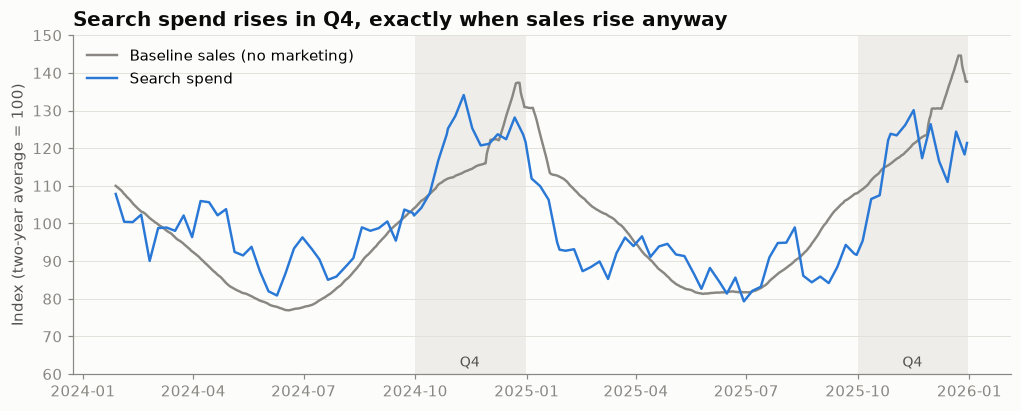

In [18]:
_, p = worlds["Always-on"]
daily = p.groupby("date")[["spend_search", "true_baseline_sales"]].sum().rolling(28).mean()
indexed = daily / daily.mean() * 100

fig, ax = plt.subplots()
ax.plot(indexed.index, indexed["true_baseline_sales"], color=style.MUTED, label="Baseline sales (no marketing)")
ax.plot(indexed.index, indexed["spend_search"], color=style.SERIES[0], label="Search spend")
for year in (2024, 2025):
    ax.axvspan(pd.Timestamp(year, 10, 1), pd.Timestamp(year, 12, 31), color=style.GRID, alpha=0.5, linewidth=0)
ax.text(pd.Timestamp(2024, 11, 15), 62, "Q4", ha="center", fontsize=9, color=style.INK_SECONDARY)
ax.text(pd.Timestamp(2025, 11, 15), 62, "Q4", ha="center", fontsize=9, color=style.INK_SECONDARY)
ax.set_title("Search spend rises in Q4, exactly when sales rise anyway")
ax.set_ylabel("Index (two-year average = 100)")
ax.set_ylim(60, 150)
ax.legend(loc="upper left")
plt.show()

**How to read it:** search spend (blue) wobbles week to week, but it climbs every Q4, the same months baseline sales (gray) climb on their own. Plot spend against sales and they move together, partly *because of the calendar*, not because of the ads. A good MMM has to separate the two by accounting for seasonality. A naive one will hand the holiday season's credit to search.

**Why the "smoothed" lines still have bumps:** each point is the average of the previous 28 days (exactly four weeks, so weekend bumps cancel out). That smooths gradual changes but not sudden ones. Black Friday is a one-day jump: it lifts the average the day it enters the 28-day window and drops it again the day it leaves, four weeks later. The steps in the gray line around late November and late December are holidays entering and leaving the window. The blue line is bumpy all year for the same reason: its budget changes every week.

### The true answers for each scenario

In [19]:
pd.DataFrame([
    {"scenario": name, **{f"true iROAS: {c}": true_iroas(p, c) for c in ["ugc", "search", "social"]}}
    for name, (_, p) in worlds.items()
]).style.format({c: "${:.2f}" for c in ["true iROAS: ugc", "true iROAS: search", "true iROAS: social"]}).hide(axis="index")

scenario,true iROAS: ugc,true iROAS: search,true iROAS: social
Hot markets,$1.69,$1.16,$1.73
Random holdout,$1.35,$1.16,$1.73
Test markets,$1.27,$1.16,$1.73
Always-on,$1.27,$1.16,$1.74


UGC's true return differs by scenario, for three reasons:
- **Hot markets, $1.69:** the regions the marketer picked are also more responsive to UGC, because of the growth–responsiveness link we assumed in section 4.
- **Random holdout, $1.35:** a random half of the regions, so close to the average region.
- **Test markets, $1.27:** these three regions happen to land near the average overall (one responsive, two less so). With only three regions, luck matters a lot: another draw could land far from it.
- **Always-on, $1.27:** some flights are small and sit on the flat start of UGC's S-curve, others are big and sit on the flattening top. Both are less efficient than the usual level. That's the "no single return on ad spend" point from section 3, showing up in practice.

So **every method gets graded against the true answer for the scenario it was run on.** And a result from one scenario doesn't automatically carry over to another.

**The simulated world is now complete.** Next we put on the analyst's hat: explore the data using **only the columns a real analyst would see** (date, region, spend, platform reports, total sales), then start measuring.

# Part II: The analyst's view

From here on we switch sides. We see **only what a real analyst would get**: date, region, spend, platform reports and total sales. The hidden truth comes out only to grade the answers.

## 6. Exploratory data analysis (EDA)

From here on, we play the analyst. The scenario is **hot markets**: marketing launched UGC in 20 regions on March 1, 2025, picked because those regions looked hot. Now they ask: **did it work?**

We get only what a real analyst would get: **date, region, spend per channel, what each ad platform reports, and total sales**. None of the hidden `true_` columns. Before reaching for any method, we do **EDA** (exploratory data analysis): look carefully at the data to check it's sane, understand its patterns, and spot traps.

In [20]:
_, panel_hot = worlds["Hot markets"]
data = analyst_view(panel_hot)

ugc_regions = data.groupby("geo")["spend_ugc"].sum() > 0
data["group"] = data["geo"].map(lambda g: "UGC regions" if ugc_regions[g] else "Other regions")

print(f"{len(data):,} rows | {data['geo'].nunique()} regions | {data['date'].min():%b %d, %Y} to {data['date'].max():%b %d, %Y}")
print(f"Missing values: {data.isna().sum().sum()} | Negative values: {(data.select_dtypes('number') < 0).sum().sum()}")
print(f"Regions that got UGC: {ugc_regions.sum()} | UGC start: {data.loc[data['spend_ugc'] > 0, 'date'].min():%b %d, %Y}")
data.head()

36,500 rows | 50 regions | Jan 01, 2024 to Dec 30, 2025
Missing values: 0 | Negative values: 0
Regions that got UGC: 20 | UGC start: Mar 01, 2025


,geo,date,spend_search,spend_social,spend_ugc,reported_search,reported_social,reported_ugc,sales,group
0,geo_00,2024-01-01,1047.950449,1154.664108,0.0,5038.141101,2318.979014,0.0,34604.387829,UGC regions
1,geo_00,2024-01-02,1047.950449,1154.664108,0.0,4986.759843,2308.642530,0.0,37815.480679,UGC regions
2,geo_00,2024-01-03,1047.950449,1154.664108,0.0,5090.911362,2329.594926,0.0,33995.731440,UGC regions
3,geo_00,2024-01-04,1047.950449,1154.664108,0.0,5038.458336,2319.042833,0.0,34098.431181,UGC regions
4,geo_00,2024-01-05,1047.950449,1154.664108,0.0,5005.999635,2312.513042,0.0,33947.966850,UGC regions


### Step 1: is the data sane?

The basic checks pass: one row per region per day, no gaps, no missing values, no negative sales or spend. With real data this step usually finds problems: days with no data because a tracking tag broke, duplicate rows, a region renamed halfway through. Our simulated data is clean, so we move on.

Next, typical values. Each of the 36,500 rows is **one region on one day**, so the table below describes a single region-day: for example, the average says how much a typical region sells (or spends on each channel) on a typical day. There's one row for sales and one for each channel's spend.

In [21]:
cols = ["sales", "spend_search", "spend_social", "spend_ugc"]
summary = data[cols].describe(percentiles=[0.5]).T[["mean", "50%", "min", "max"]]
summary.columns = ["average", "median", "min", "max"]
summary.index = ["Sales", "Search spend", "Social spend", "UGC spend"]
summary.index.name = "One region, one day"
summary.style.format("${:,.0f}")

,average,median,min,max
"One region, one day",,,,
Sales,"$29,026","$26,403","$5,213","$170,101"
Search spend,"$1,265","$1,147",$192,"$5,842"
Social spend,"$1,013",$915,$150,"$5,501"
UGC spend,$77,$0,$0,"$1,446"


UGC's median is $0 because most region-days had no UGC spend: 30 regions never got it, and the other 20 only from March through November 2025.

### Step 2: the big picture

### Chart 8: national sales and spend, week by week

Two panels sharing the same timeline: total weekly sales on top, weekly spend by channel below. (Sales and spend are in very different amounts, so they get separate panels instead of sharing one axis.)

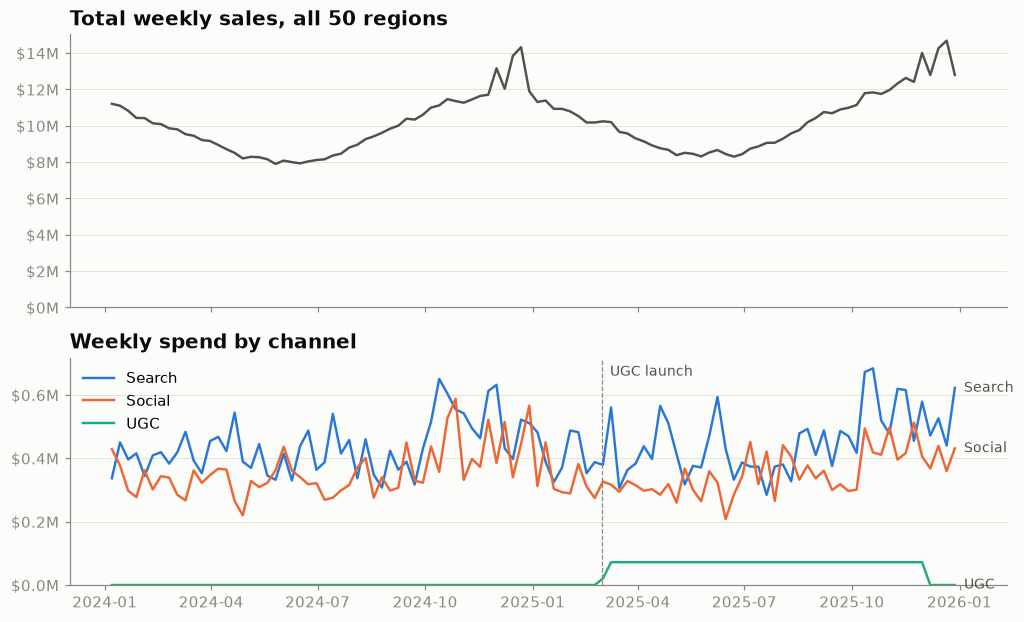

In [22]:
weekly = data.set_index("date")[cols].resample("W").sum() / 1e6
weekly = weekly.iloc[:-1]  # drop the partial last week (data ends on a Tuesday)

fig, (top, bottom) = plt.subplots(2, 1, figsize=(11, 6.5), sharex=True, height_ratios=[1.2, 1])
top.plot(weekly.index, weekly["sales"], color=style.INK_SECONDARY)
top.set_title("Total weekly sales, all 50 regions")
top.yaxis.set_major_formatter(mticker.FormatStrFormatter("$%.0fM"))
top.set_ylim(bottom=0)

for col, label, color in [("spend_search", "Search", style.SERIES[0]), ("spend_social", "Social", style.SERIES[1]),
                          ("spend_ugc", "UGC", style.SERIES[2])]:
    bottom.plot(weekly.index, weekly[col], color=color, label=label)
    bottom.annotate(label, (weekly.index[-1], weekly[col].iloc[-1]), xytext=(6, 0), textcoords="offset points",
                    va="center", fontsize=9, color=style.INK_SECONDARY)
bottom.axvline(pd.Timestamp("2025-03-01"), color=style.MUTED, linewidth=0.8, linestyle="--")
bottom.text(pd.Timestamp("2025-03-08"), bottom.get_ylim()[1] * 0.92, "UGC launch", fontsize=9, color=style.INK_SECONDARY)
bottom.set_title("Weekly spend by channel")
bottom.yaxis.set_major_formatter(mticker.FormatStrFormatter("$%.1fM"))
bottom.set_ylim(bottom=0)
bottom.legend(loc="upper left")
bottom.set_xlim(right=weekly.index[-1] + pd.Timedelta(days=45))
plt.show()

**What we see:**
- **Sales** follow the familiar pattern: a summer dip, a holiday peak, and a higher second year.
- **Search and social** run all the time, wobble week to week, and step up every Q4.
- **UGC** runs from March through November 2025. It's much smaller than the other two: it runs in only 20 regions, at a lower budget.

Nothing here can answer "did UGC work?" National sales were rising into the holidays anyway. We need to compare the regions that got UGC with the ones that didn't.

### Step 3: looking for traps

### Chart 9: UGC regions vs other regions, over time

Total sales of the 20 UGC regions and of the 30 others, each indexed to its own first 28 days (100 = its January 2024 level) and smoothed over 28 days.

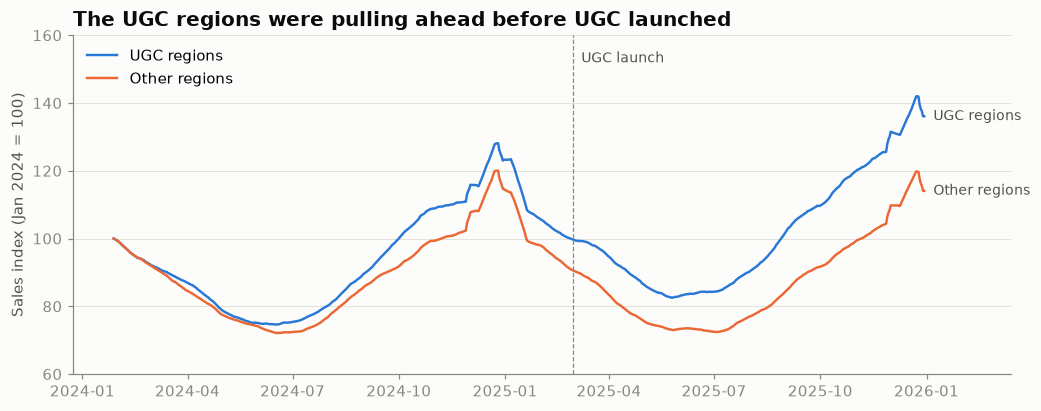

In [23]:
by_group = data.groupby(["date", "group"])["sales"].sum().unstack()
indexed = by_group.rolling(28).mean() / by_group.iloc[:28].mean() * 100
colors = {"UGC regions": style.SERIES[0], "Other regions": style.SERIES[1]}

fig, ax = plt.subplots()
for name in ["UGC regions", "Other regions"]:
    s = indexed[name]
    ax.plot(s.index, s.values, color=colors[name], label=name)
    ax.annotate(name, (s.index[-1], s.iloc[-1]), xytext=(6, 0), textcoords="offset points",
                va="center", fontsize=9, color=style.INK_SECONDARY)
ax.axvline(pd.Timestamp("2025-03-01"), color=style.MUTED, linewidth=0.8, linestyle="--")
ax.text(pd.Timestamp("2025-03-08"), 152, "UGC launch", fontsize=9, color=style.INK_SECONDARY)
ax.set_title("The UGC regions were pulling ahead before UGC launched")
ax.set_ylabel("Sales index (Jan 2024 = 100)")
ax.set_ylim(60, 160)
ax.legend(loc="upper left")
ax.set_xlim(right=indexed.index[-1] + pd.Timedelta(days=75))
plt.show()

**This is the most important chart in the EDA.** The two groups start together in January 2024, but the blue line (UGC regions) **pulls ahead throughout 2024, before any UGC money was spent**. By the launch date it's already about 9 points higher. After launch the gap keeps widening.

So the gap after launch is a mix of two things that look identical in the data:
1. The UGC regions' head start, which would have kept growing anyway.
2. Whatever UGC actually added.

### Chart 10: same months, one year apart

A cleaner check compares each region's average daily sales with *its own* average a year earlier, over the same months, which removes seasonality. (Daily averages rather than totals, because 2024 was a leap year: January–February 2024 has one more day.) Each dot is one region:
- **Before launch:** January–February 2025 vs January–February 2024.
- **After launch:** March–December 2025 vs March–December 2024.

The short horizontal lines are each group's average.

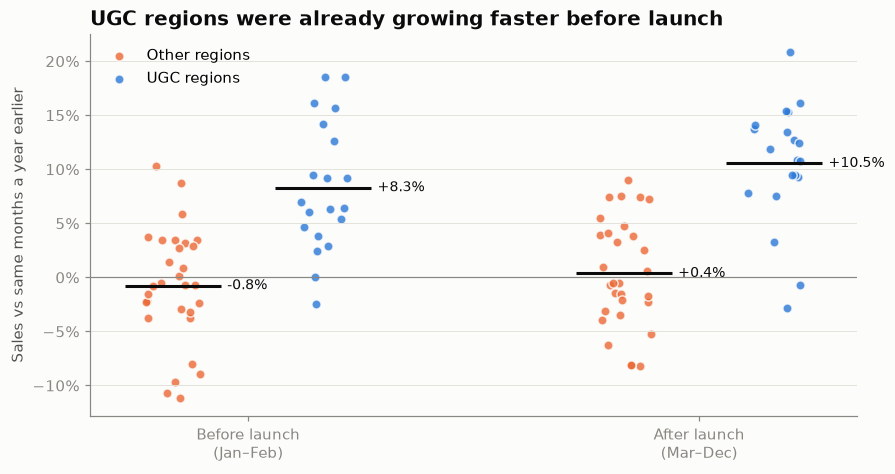

In [24]:
def yoy_growth(start_prev, end_prev, start_this, end_this):
    # Average DAILY sales, not totals: 2024 was a leap year, so Jan-Feb 2024 has one more day than Jan-Feb 2025.
    prev = data[data["date"].between(start_prev, end_prev)].groupby("geo")["sales"].mean()
    this = data[data["date"].between(start_this, end_this)].groupby("geo")["sales"].mean()
    return this / prev - 1

growth = pd.DataFrame({
    "Before launch\n(Jan–Feb)": yoy_growth("2024-01-01", "2024-02-29", "2025-01-01", "2025-02-28"),
    "After launch\n(Mar–Dec)": yoy_growth("2024-03-01", "2024-12-30", "2025-03-01", "2025-12-30"),
})
growth["group"] = ugc_regions.map({True: "UGC regions", False: "Other regions"})

rng_jitter = np.random.default_rng(0)
fig, ax = plt.subplots(figsize=(9, 4.5))
for i, period in enumerate(growth.columns[:2]):
    for j, name in enumerate(["Other regions", "UGC regions"]):
        vals = growth.loc[growth["group"] == name, period]
        x = i * 3 + j + rng_jitter.uniform(-0.18, 0.18, len(vals))
        ax.scatter(x, vals, s=36, color=colors[name], alpha=0.8, edgecolor=style.SURFACE, linewidth=1,
                   label=name if i == 0 else None)
        ax.hlines(vals.mean(), i * 3 + j - 0.32, i * 3 + j + 0.32, color=style.INK, linewidth=2)
        ax.annotate(f"{vals.mean():+.1%}", (i * 3 + j + 0.36, vals.mean()), va="center", fontsize=9, color=style.INK)
ax.axhline(0, color=style.MUTED, linewidth=0.8)
ax.set_xticks([0.5, 3.5], growth.columns[:2])
ax.yaxis.set_major_formatter(mticker.PercentFormatter(1.0, decimals=0))
ax.set_ylabel("Sales vs same months a year earlier")
ax.set_title("UGC regions were already growing faster before launch")
ax.legend(loc="upper left")
ax.grid(axis="x", visible=False)
plt.show()

**What we see:**
- **Before launch**, UGC regions were already up about **+8.3%** on the year before, while the other regions were roughly flat (about **−0.8%**). That's a gap of about **9 points before any UGC ran**.
- **After launch**, the gap is about **10 points** (+10.5% vs +0.4%).

A naive analyst would say "UGC regions grew 10 points faster after launch, so UGC drove a 10-point lift." But **9 of those points were there before UGC started.**

A smarter move is to subtract the head start: 10.2 − 9.1 ≈ **1 point**. This compares the groups' growth *gap* after launch with their growth gap before, so it allows the two groups to grow at different speeds, as long as each keeps its own speed. It's a trend-adjusted version of **difference-in-differences**, a method we'll meet properly in the next sections. Here, growth rates mostly hold steady but sales levels also wander, and sticky shocks move whole regions for weeks, so two months of "before" data is a shaky baseline.

*Spoiler from the hidden truth:* UGC's real lift in these regions was about **2.3 points**. The naive answer (10 points) is four times too big. The subtraction (1 point) is in the right ballpark, but **noisy**: we reran the whole world with 30 different random seeds, and this subtraction was right *on average* but typically missed by about 2 points either way. In this world it happened to land low; in another it could land at 4. The methods ahead are about doing better than both.

### What the EDA tells us before we model anything

1. **The data is clean.** It has no gaps or obvious errors.
2. **National numbers can't answer the question.** Sales rise into every holiday season regardless of UGC.
3. **The UGC regions are not comparable to the others.** They were growing faster before launch, which is the confounding trap from the hot-markets scenario, now visible from the analyst's side.
4. **This warning sign has a name: a pre-trend.** When the treated group is already moving differently before the treatment, simple treated-vs-untreated comparisons will be badly biased.
5. **The effect is small relative to the noise.** A real 2–3% lift is easily swamped by region-to-region differences and sticky shocks, which is why careful methods matter.

**Next:** the naive methods. We'll compute the numbers a typical dashboard would show (last-click attribution, a before/after comparison, a simple regression) and grade each one against the true answer for hot markets, **$1.69** per $1.

# Part III: Measuring the effect

Now we answer the business question: **how much revenue did each $1 of UGC create?** Each method gets run on the scenario it's designed for, and graded against that scenario's true answer:

| Section | Method | Scenario | Why this pairing |
|---|---|---|---|
| 7 | Naive methods | Hot markets | What a typical team would do with the data it has, trap included |
| 8 | Geo experiment + CUPED | Random holdout | A coin flip picked the UGC regions, the setup experiments need |
| 9 | Difference-in-differences | Hot markets | Can a careful comparison rescue the trap, once we check for a pre-trend? |
| 10 | Synthetic control | Test markets | Only 3 regions got UGC, so each needs a lookalike built from the rest |
| 11 | Marketing mix model | Always-on | No control group, but spend that rises and falls, which is what an MMM learns from |
| 12 | Monte Carlo study | All of them | Rerun across many random worlds, to separate methods that are right from ones that got lucky |

## 7. Naive methods: what a typical team would report

Still playing the analyst in the hot-markets scenario, we now try four common ways of answering "what did UGC return per $1?". None of them is crazy; each shows up in real decks. We grade each one against the hidden truth for hot markets: **$1.69 per $1**.

1. **Last-click attribution:** read the UGC number off the ad platform's dashboard.
2. **Before vs after:** compare UGC regions' sales this year with the same months last year, and credit all the growth to UGC.
3. **UGC regions vs the rest:** credit UGC with the whole gap in growth between the regions that got it and those that didn't. (This is already a basic difference-in-differences.)
4. **A simple regression:** fit daily sales against daily spend on each channel, across every region and day, first with no other controls, then with controls for region and day.

All four estimates are expressed the same way: **extra revenue per $1 of UGC spend**. The outcome window is March 1 – December 30, 2025, which covers the campaign (March–November) plus its fading tail.

In [25]:
ugc_spend = data["spend_ugc"].sum()
truth_hot = true_iroas(panel_hot, "ugc")  # hidden truth, used only for grading
treated = data["group"] == "UGC regions"
after = data["date"].between("2025-03-01", "2025-12-30")
year_before = data["date"].between("2024-03-01", "2024-12-30")  # same 305 days a year earlier

scoreboard = {}  # method -> estimated return per $1; we add to this in every section
print(f"UGC spend in hot markets: ${ugc_spend:,.0f}  |  True return: ${truth_hot:.2f} per $1")

UGC spend in hot markets: $2,825,639  |  True return: $1.69 per $1


### Method 1: last-click attribution

The simplest answer: take the revenue the ad platform says UGC drove and divide by spend.

In [26]:
scoreboard["Last-click (dashboard)"] = data["reported_ugc"].sum() / ugc_spend

channels = ["search", "social", "ugc"]
pd.DataFrame({
    "channel": ["Paid search", "Paid social", "UGC"],
    "dashboard says (per $1)": [data[f"reported_{c}"].sum() / data[f"spend_{c}"].sum() for c in channels],
    "truth (per $1)": [true_iroas(panel_hot, c) for c in channels],
}).style.format({"dashboard says (per $1)": "${:.2f}", "truth (per $1)": "${:.2f}"}).hide(axis="index")

channel,dashboard says (per $1),truth (per $1)
Paid search,$2.90,$1.16
Paid social,$1.35,$1.73
UGC,$0.09,$1.69


The dashboard credits UGC with about **$0.09 per $1**, roughly **19× too low**. Two things go wrong at once:
- **UGC's own sales rarely end with a click on UGC.** People watch a video, remember the brand, and buy days later through some other route.
- **UGC's halo is credited to search.** Viewers who later google the brand click a search ad, and search takes the credit. That, plus loyal customers clicking the top search ad on their way in, is why search's dashboard number is more than double its true return.

Last-click doesn't measure what ads *cause*. It measures which ad sat closest to the purchase.

### Method 2: before vs after

Compare the UGC regions' sales after launch with the same months a year earlier, and credit the whole increase to UGC. Using the same months removes seasonality.

In [27]:
sales_after = data.loc[after & treated, "sales"].sum()
sales_before = data.loc[year_before & treated, "sales"].sum()
scoreboard["Before vs after"] = (sales_after - sales_before) / ugc_spend

print(f"UGC regions' sales grew {sales_after / sales_before - 1:+.1%} year over year "
      f"(${(sales_after - sales_before) / 1e6:,.1f}M), credited entirely to ${ugc_spend / 1e6:,.1f}M of UGC")
print(f"Estimate: ${scoreboard['Before vs after']:.2f} per $1")

UGC regions' sales grew +11.1% year over year ($21.6M), credited entirely to $2.8M of UGC
Estimate: $7.65 per $1


This gives about **$7.65 per $1, 4.5× too high**. The UGC regions grew 11% year over year, but most of that would have happened anyway: these are the hot markets, growing fast before UGC existed. Before vs after has no way to separate "UGC worked" from "this region was growing."

### Method 3: UGC regions vs the rest

A step up: use the other 30 regions as a comparison. Credit UGC with the *gap* between the two groups' growth, not the whole increase.

In [28]:
other_after = data.loc[after & ~treated, "sales"].sum()
other_before = data.loc[year_before & ~treated, "sales"].sum()
growth_ugc = sales_after / sales_before - 1
growth_other = other_after / other_before - 1
scoreboard["UGC regions vs the rest"] = (growth_ugc - growth_other) * sales_before / ugc_spend

print(f"Growth: UGC regions {growth_ugc:+.1%}, other regions {growth_other:+.1%}, gap {growth_ugc - growth_other:+.1%}")
print(f"Estimate: ${scoreboard['UGC regions vs the rest']:.2f} per $1")

Growth: UGC regions +11.1%, other regions -0.5%, gap +11.5%
Estimate: $7.96 per $1


Still about **$7.96 per $1**. The comparison group took out the *national* trend, but here the national trend wasn't the problem: the other regions were flat.

**This method has a name: difference-in-differences** (DiD). It takes two differences: each group's change from last year to this year, then the difference between those changes. DiD rests on one assumption, called **parallel trends**: without the campaign, both groups would have changed by the same amount. Here that's false. The UGC regions were picked for being hot, so they were already growing about 9 points a year faster (we saw it in the EDA), and DiD credits all of that to UGC. Plain DiD is only as good as that assumption, which is why the DiD section later starts by checking for a pre-trend.

(The growth figures here are for each group's *total* sales, which weights big regions more, so they differ a little from the EDA's region-by-region averages.)

### Method 4: a simple regression

Fit one equation across all 36,500 region-days:

**sales = intercept + b₁ × search spend + b₂ × social spend + b₃ × UGC spend**

and read b₃ as "extra sales per $1 of UGC". This is a common first move for anyone with a stats background.

In [29]:
naive_model = smf.ols("sales ~ spend_search + spend_social + spend_ugc", data=data)
by_region = {"groups": data["geo"].astype("category").cat.codes}  # rows from the same region count as one group

plain = naive_model.fit()                                             # treats every row as independent
clustered = naive_model.fit(cov_type="cluster", cov_kwds=by_region)  # same estimate, honest interval
b = plain.params["spend_ugc"]
scoreboard["Simple regression"] = b

def interval(fit, name="spend_ugc"):
    est, se = fit.params[name], fit.bse[name]
    return f"${est - 1.96 * se:.2f} to ${est + 1.96 * se:.2f}"

print(f"UGC: ${b:.2f} per $1")
print(f"  95% interval if every row were independent: {interval(plain)}")
print(f"  95% interval clustered by region:           {interval(clustered)}")
print(f"Search: ${plain.params['spend_search']:.2f} per $1 (truth ${true_iroas(panel_hot, 'search'):.2f})")
print(f"Social: ${plain.params['spend_social']:.2f} per $1 (truth ${true_iroas(panel_hot, 'social'):.2f})")

UGC: $7.39 per $1
  95% interval if every row were independent: $7.07 to $7.72
  95% interval clustered by region:           $5.70 to $9.08
Search: $9.79 per $1 (truth $1.16)
Social: $13.65 per $1 (truth $1.73)


In [30]:
# The full table a statistician would check first (standard errors clustered by region)
print(clustered.summary())

                            OLS Regression Results                            
Dep. Variable:                  sales   R-squared:                       0.827
Model:                            OLS   Adj. R-squared:                  0.827
Method:                 Least Squares   F-statistic:                     382.7
Date:                Sun, 01 Nov 2026   Prob (F-statistic):           5.51e-34
Time:                        01:11:41   Log-Likelihood:            -3.7180e+05
No. Observations:               36500   AIC:                         7.436e+05
Df Residuals:                   36496   BIC:                         7.436e+05
Df Model:                           3                                         
Covariance Type:              cluster                                         
                   coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------
Intercept     2239.3973    886.306      2.527   

**Reading the full output.** This is the standard table people check first, and at first glance it looks great:
- **R-squared = 0.83:** the model explains 83% of the variation in daily sales.
- **Every spend coefficient has P>|z| = 0.000:** all three channels look clearly "significant".

That's the trap. R-squared measures how well the model **fits** sales, not whether it gets **cause and effect** right. Most of this fit comes from "big regions spend more and sell more", which says nothing about whether ads work. A p-value only says the coefficient isn't zero; it can't tell you the coefficient is aimed at the wrong thing.

A few lines further down do hint at trouble, if you know to look:
- **Durbin-Watson = 0.38.** It checks whether each row's error resembles the previous row's. Around 2 means independent; near 0 means strongly linked. Consecutive days in a region have similar errors: that's the sticky shocks.
- **Skew and kurtosis** (1.3 and 10.9, where a normal bell curve has 0 and 3): the errors have long tails, from holiday spikes and from big regions having bigger dollar swings.
- **The condition number warning:** the three spend columns move together (all scale with region size), so the model struggles to tell them apart.

None of these warnings says "your UGC estimate is 4× too high". They say the model's assumptions are broken, which is a reason to distrust it.

The regression says UGC returns about **$7.39 per $1**. Search and social come out absurdly high too.

**About the confidence interval.** The first interval ($7.07 to $7.72) looks very tight, but it assumes all 36,500 rows are independent pieces of evidence. They aren't. Sticky shocks mean a region's good weeks come in runs, so 730 days from one region carry far less information than 730 separate regions would. The standard fix is **clustered standard errors**: treat all the rows from one region as one related group. The interval widens to about **$5.70 to $9.08**. That's more honest, and it still comes nowhere near the truth of $1.69. The regression is **confidently wrong**.

Why? The regression assumes that spend is the only reason sales differ between rows. But:
- **Bigger regions spend more and sell more.** Every budget is set as a share of region size, so spend and sales rise together across regions for reasons that have nothing to do with ads working. The regression reads "big regions" as "ads work".
- **Spend rises in Q4, and so do sales,** because of the holidays.
- **UGC went to hot regions,** which were growing anyway.

All three push spend and sales in the same direction, and the regression credits the ads with all of it. Even an honest confidence interval only measures how much the estimate would wobble from random noise. It says nothing about bias: if the method is aimed at the wrong target, more data just makes it more confidently wrong.

### Method 4b: the same regression with region and day controls

Anyone with regression training would add controls for the first two problems: a separate baseline for each region (**region fixed effects**, so "big regions sell more" is absorbed) and a separate baseline for each day (**date fixed effects**, so "the holidays lift everyone" is absorbed). Then b₃ only learns from how spend and sales move *within* a region, relative to the national day.

In [31]:
# C(geo) and C(date) add one baseline per region and one per day (about 780 extra terms).
fe_model = smf.ols("sales ~ spend_search + spend_social + spend_ugc + C(geo) + C(date)", data=data)
fe_fit = fe_model.fit(cov_type="cluster", cov_kwds=by_region)
scoreboard["Regression + region & day controls"] = fe_fit.params["spend_ugc"]

print(f"UGC: ${fe_fit.params['spend_ugc']:.2f} per $1 (95% interval clustered by region: {interval(fe_fit)})")
print(f"Search: ${fe_fit.params['spend_search']:.2f} per $1  |  Social: ${fe_fit.params['spend_social']:.2f} per $1")
print(f"R-squared: {fe_fit.rsquared:.2f}")

UGC: $4.41 per $1 (95% interval clustered by region: $3.36 to $5.46)
Search: $3.24 per $1  |  Social: $5.02 per $1
R-squared: 0.95


Better, at **$4.41 per $1**, but still **2.6× too high**, even though R-squared climbs to **0.95**, and the interval ($3.36 to $5.46) still excludes the truth. The controls fixed what they were designed for, but two problems remain:
- **Hot regions grow faster.** A region baseline is a fixed level. It can't absorb a region that keeps pulling ahead month after month, and that's exactly where UGC went.
- **Seasons hit big regions harder in dollars.** A +20% December adds $12,000 a day to a $60,000 region and $1,200 to a $6,000 one, and budgets also rise in Q4 in proportion to size. A single baseline per day can't capture that, which is why search and social are still well above their true returns.

Controls only help with the problems you control for. The trap here, budget following momentum, needs a different design.

### The scoreboard so far

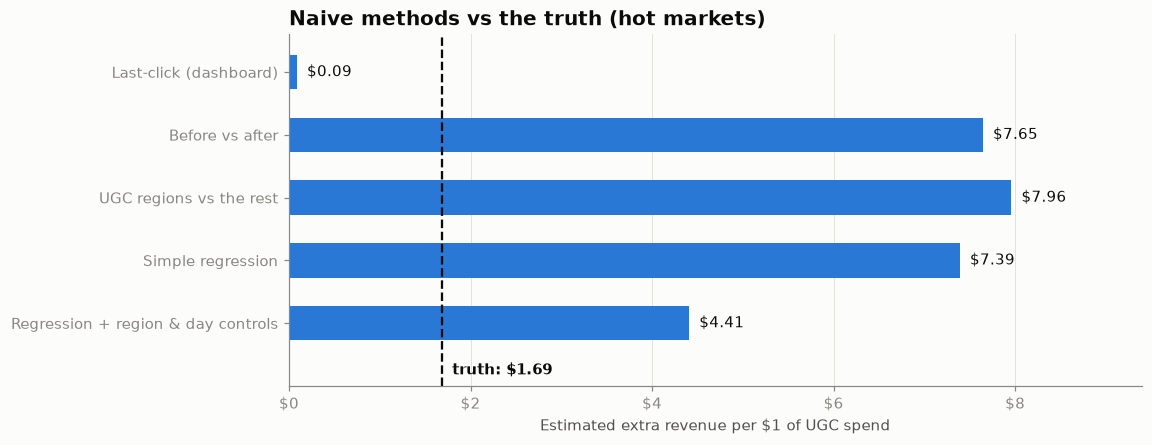

In [32]:
def plot_scoreboard(scores, truth, title):
    names = list(scores)[::-1]
    vals = [scores[n] for n in names]
    fig, ax = plt.subplots(figsize=(10, 0.55 * len(names) + 1.4))
    ax.barh(names, vals, color=style.SERIES[0], height=0.55)
    ax.axvline(truth, color=style.INK, linewidth=1.5, linestyle="--")
    ax.set_ylim(-1.0, len(names) - 0.4)
    ax.text(truth, -0.75, f"  truth: ${truth:.2f}", color=style.INK, fontsize=10, va="center", fontweight="bold")
    for i, v in enumerate(vals):
        ax.text(v, i, f"  ${v:.2f}", va="center", fontsize=10, color=style.INK)
    ax.set_xlim(0, max(vals + [truth]) * 1.18)
    ax.xaxis.set_major_formatter(mticker.FormatStrFormatter("$%.0f"))
    ax.set_xlabel("Estimated extra revenue per $1 of UGC spend")
    ax.grid(axis="y", visible=False)
    ax.grid(axis="x", visible=True)
    ax.set_axisbelow(True)
    ax.set_title(title)
    plt.show()

plot_scoreboard(scoreboard, truth_hot, "Naive methods vs the truth (hot markets)")

**Two opposite failures:**
- **Attribution under-credits UGC** (19× too low), because it follows clicks, not causes. A team trusting it would cut a campaign that works.
- **Naive comparisons and regressions over-credit UGC** (2.6–4.7× too high), because UGC went to regions that were already growing, and bigger regions spend and sell more. Adding controls narrows the gap but doesn't close it. A team trusting them would pour money into UGC expecting returns that won't come.

Neither failure is visible from inside the method. Each produces a clean, confident number, and even an honest confidence interval can't flag bias.

**Next:** methods built to handle these problems. First, the **randomized geo experiment** (the random-holdout scenario), where a coin flip, not a marketer, decides which regions get UGC, and **CUPED** sharpens the answer. We'll also ask how often a test this size detects the effect at all, because one simulated world can be lucky.